# Linear regression, workshop 1 — The line, the cost, and the exact answer

**The situation.** You run a bakery. Some days you sell 40 iced coffees, some days 120, and you
would like to know how many to prepare tomorrow. You have a year of daily records: the afternoon
temperature, and the number of iced coffees sold.

Plot one against the other and a pattern appears. Today we turn that pattern into a model, and
then into *the best possible* model — exactly, with no searching.

1. **The hypothesis** — a line, written as code.
2. **The cost** — a single number saying how wrong a line is.
3. **The exact solution** — calculus hands you the best line directly.
4. **The residuals** — where the model is still wrong, and what that tells you.

Everything here is the machinery behind your `my_linear_regression` project. We use a different
dataset on purpose: the ideas transfer, the code you submit stays yours to write.

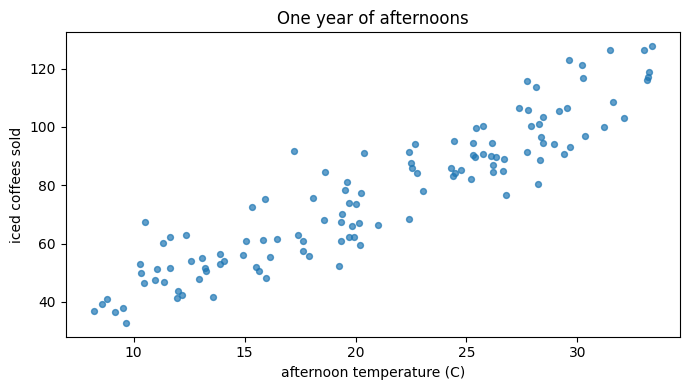

In [ ]:
# ABOUTME: Linear regression workshop 1 - hypothesis, mean squared error, normal equation, residuals.
# ABOUTME: Bakery scenario: predicting iced-coffee sales from the afternoon temperature.
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

def ready(*values):
    """True once the exercises a cell depends on have been filled in."""
    return all(v is not None for v in values)

n = 120
temperature = rng.uniform(8, 34, n)                      # degrees Celsius
sales = 12 + 3.1 * temperature + rng.normal(0, 9, n)     # the rule we are trying to rediscover
sales = np.maximum(sales, 0)

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(temperature, sales, s=18, alpha=0.7)
ax.set_xlabel("afternoon temperature (C)"); ax.set_ylabel("iced coffees sold")
ax.set_title("One year of afternoons")
plt.tight_layout()

## 1. The hypothesis is a line

A linear model says: *prediction = intercept + slope x feature*.

$$\hat{y} = \theta_0 + \theta_1 x$$

- $\theta_0$ (**intercept**): sales at 0 C — where the line crosses the vertical axis.
- $\theta_1$ (**slope**): extra coffees per extra degree.

Two numbers. That is the entire model, and "training" means choosing them well.

**Rule of thumb:** always read the parameters out loud in the units of the problem. "3.1 coffees
per degree" is a sentence you can check against reality; "theta_1 = 3.1" is not.

### Exercise 1 — the prediction function

Write `predict(x, theta)` where `theta` is the pair `(intercept, slope)`. It must work on a whole
array of temperatures at once — no Python loop.

In [ ]:
def predict(x, theta):
    """Predicted sales for each temperature in x. theta = (intercept, slope)."""
    intercept, slope = theta
    return intercept + slope * np.asarray(x)

print(predict(np.array([10.0, 20.0, 30.0]), (12.0, 3.1)))

[ 43.  74. 105.]


In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

check("one prediction per input", lambda: predict(np.array([1.0, 2.0]), (0.0, 1.0)).shape == (2,))
check("intercept only", lambda: np.allclose(predict(np.array([0.0, 5.0]), (7.0, 0.0)), [7.0, 7.0]))
check("slope applied", lambda: np.allclose(predict(np.array([2.0]), (1.0, 3.0)), [7.0]))

  one prediction per input: PASS
  intercept only: PASS
  slope applied: PASS


True

## 2. The cost: one number for "how wrong"

Three different lines through the same cloud. Which is best? You cannot answer by eye, and "best"
has to mean something precise before you can optimise it.

For each point, the **error** is what you predicted minus what happened. Square the errors (so that
being 10 too high is as bad as 10 too low, and so that big misses hurt disproportionately), then
average them:

$$\text{MSE}(\theta) = \frac{1}{m}\sum_{i=1}^{m}\left(\hat{y}^{(i)} - y^{(i)}\right)^2$$

RMSE is its square root, which has the nice property of being in coffees rather than coffees
squared. Minimising either gives the same $\theta$, because the square root is increasing.

### Exercise 2 — mean squared error

Write `mse(y_pred, y_true)`. Check it by hand first: for predictions `[2, 4]` against truth
`[3, 3]`, the errors are `-1` and `+1`, so the MSE is `(1 + 1) / 2 = 1`.

In [ ]:
def mse(y_pred, y_true):
    """Mean of the squared differences between predictions and truth."""
    return float(np.mean((np.asarray(y_pred) - np.asarray(y_true)) ** 2))

print("hand-checked case:", mse(np.array([2.0, 4.0]), np.array([3.0, 3.0])), "(should be 1.0)")

hand-checked case: 1.0 (should be 1.0)


In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

check("the hand-checked case", lambda: abs(mse(np.array([2.0, 4.0]), np.array([3.0, 3.0])) - 1.0) < 1e-12)
check("a perfect fit costs nothing", lambda: mse(np.array([5.0, 6.0]), np.array([5.0, 6.0])) == 0)
check("symmetric: too high and too low cost the same",
      lambda: mse(np.array([4.0]), np.array([3.0])) == mse(np.array([2.0]), np.array([3.0])))

  the hand-checked case: PASS
  a perfect fit costs nothing: PASS
  symmetric: too high and too low cost the same: PASS


True

Now compare candidate lines with a number instead of an opinion.

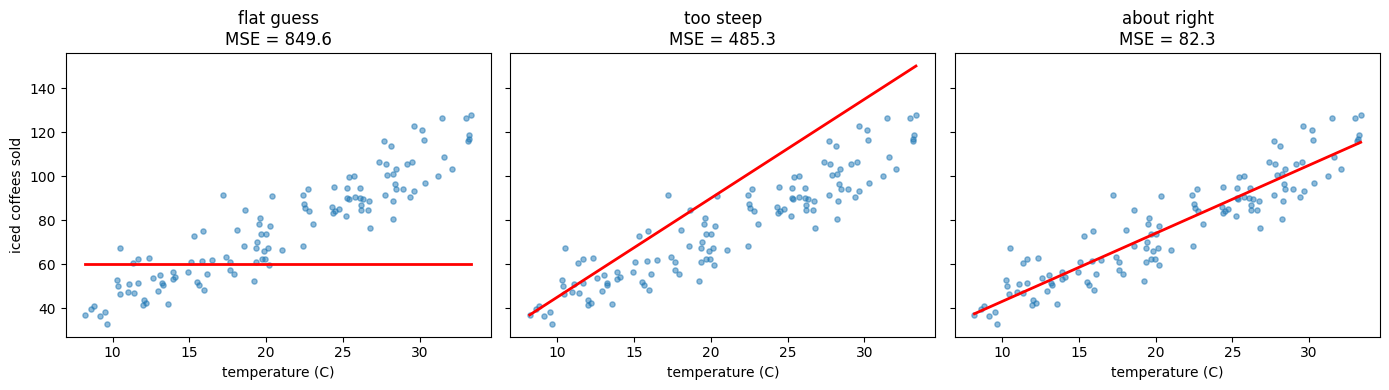

In [ ]:
candidates = {"flat guess": (60.0, 0.0), "too steep": (0.0, 4.5), "about right": (12.0, 3.1)}
grid = np.linspace(temperature.min(), temperature.max(), 50)

if not ready(predict(grid, (0.0, 1.0)), mse(np.array([1.0]), np.array([1.0]))):
    print("Finish exercises 1 and 2, then run this cell.")
else:
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
    for ax, (label, theta) in zip(axes, candidates.items()):
        ax.scatter(temperature, sales, s=14, alpha=0.5)
        ax.plot(grid, predict(grid, theta), "r-", lw=2)
        ax.set_title(f"{label}\nMSE = {mse(predict(temperature, theta), sales):.1f}")
        ax.set_xlabel("temperature (C)")
    axes[0].set_ylabel("iced coffees sold")
    plt.tight_layout()

**The punchline:** the cost function turns "that line looks better" into a number you can compare,
and anything you can compare you can optimise.

### Try it yourself

Drag the sliders. See how far you can push the MSE down by hand — and notice how flat the cost
feels near the bottom, which is exactly why a computer finds the minimum faster than you do.

In [ ]:
from ipywidgets import interact, FloatSlider

@interact(intercept=FloatSlider(min=-40, max=80, step=1, value=60),
          slope=FloatSlider(min=-2, max=8, step=0.1, value=0))
def show_line(intercept, slope):
    guess = predict(grid, (intercept, slope))
    if not ready(guess):
        print("Finish exercises 1 and 2 to make the sliders work.")
        return
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.scatter(temperature, sales, s=16, alpha=0.6)
    ax.plot(grid, guess, "r-", lw=2)
    ax.set_title(f"MSE = {mse(predict(temperature, (intercept, slope)), sales):.1f}")
    ax.set_xlabel("temperature (C)"); ax.set_ylabel("iced coffees sold")
    plt.show()

interactive(children=(FloatSlider(value=60.0, description='intercept', max=80.0, min=-40.0, step=1.0), FloatSl…

## 3. The exact answer

For a straight line you do not have to search at all. The MSE is a parabola in $\theta$ — one
bottom, no local traps — so setting its derivative to zero gives the answer in closed form:

$$\theta_1 = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sum (x_i - \bar{x})^2}
\qquad
\theta_0 = \bar{y} - \theta_1 \bar{x}$$

The slope is "how x and y move together" divided by "how much x moves on its own". The intercept
then places the line so it passes through the mean point $(\bar{x}, \bar{y})$ — a useful fact:
**every least-squares line goes through the centre of mass of the data.**

### Exercise 3 — solve it exactly

In [ ]:
def least_squares(x, y):
    """Return (intercept, slope) minimising the MSE, using the closed form above."""
    x, y = np.asarray(x), np.asarray(y)
    dx, dy = x - x.mean(), y - y.mean()
    slope = float((dx * dy).sum() / (dx ** 2).sum())
    intercept = float(y.mean() - slope * x.mean())
    return intercept, slope

theta_hat = least_squares(temperature, sales)
print("theta:", theta_hat, " <- the data was generated with intercept 12, slope 3.1")

theta: (12.020978009336872, 3.09513742111391)  <- the data was generated with intercept 12, slope 3.1


In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

check("returns two numbers", lambda: len(theta_hat) == 2)
check("recovers the generating slope", lambda: abs(theta_hat[1] - 3.1) < 0.4)
check("beats every candidate line",
      lambda: mse(predict(temperature, theta_hat), sales) < min(mse(predict(temperature, t), sales)
                                                                for t in candidates.values()))
check("the line passes through the mean point",
      lambda: abs(predict(np.array([temperature.mean()]), theta_hat)[0] - sales.mean()) < 1e-9)

  returns two numbers: PASS
  recovers the generating slope: PASS
  beats every candidate line: PASS
  the line passes through the mean point: PASS


True

No iterations, no learning rate, no waiting: the best line, straight from the data.

### What about many features?

With several features you cannot write "the" slope, so the same derivation is done in matrix form
and gives the **normal equation**:

$$\theta = (X^T X)^{-1} X^T y$$

where $X$ has one row per observation and one column per feature — plus a **column of ones** so
that $\theta_0$ becomes an ordinary weight instead of a special case. That bias column is the trick
that lets a single matrix multiplication express "intercept plus slopes".

Generalising this into a reusable class is your project; here is the one-line version, so you can
see that it produces exactly what you just computed by hand.

In [ ]:
X = np.column_stack([np.ones(n), temperature])        # the bias column, then the feature
theta_matrix = np.linalg.pinv(X.T @ X) @ X.T @ sales

print("normal equation       :", np.round(theta_matrix, 6))
if ready(theta_hat):
    print("closed form, by hand  :", np.round(theta_hat, 6))
    print("same answer           :", np.allclose(theta_hat, theta_matrix))
else:
    print("closed form, by hand  : finish exercise 3 to compare the two")

normal equation       : [12.020978  3.095137]
closed form, by hand  : [12.020978  3.095137]
same answer           : True


Note `pinv` rather than `inv`: the pseudo-inverse returns a sensible answer even when $X^T X$
cannot be inverted (two identical features, or fewer rows than columns), where `inv` simply raises.

**Rule of thumb:** if the exact solution exists and your data fits in memory, use it. Gradient
descent — next workshop — earns its place when $X^T X$ is too big to invert, or when the model is
not linear and no closed form exists.

## 4. Residuals: where the model is still wrong

The MSE is one number for the whole dataset. Residuals — $y - \hat{y}$, one per point — tell you
*where* the error lives. Plot them against the prediction and you are looking for **nothing**:
a shapeless band around zero. Any pattern is signal the model failed to capture.

### Exercise 4 — compute and read the residuals

In [ ]:
def residuals(x, y, theta):
    """Actual minus predicted, one per observation."""
    return np.asarray(y) - predict(x, theta)

res = residuals(temperature, sales, theta_hat)
print("mean residual:", round(float(np.mean(res)), 10))

mean residual: -0.0


In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

check("one residual per point", lambda: res.shape == sales.shape)
check("least-squares residuals average to zero", lambda: abs(float(np.mean(res))) < 1e-9)

  one residual per point: PASS
  least-squares residuals average to zero: PASS


True

That second check is not a coincidence: a least-squares fit with an intercept **always** leaves
residuals summing to zero. If yours do not, you have a bug, not a bad model.

Below: your residuals, next to two broken models for comparison.

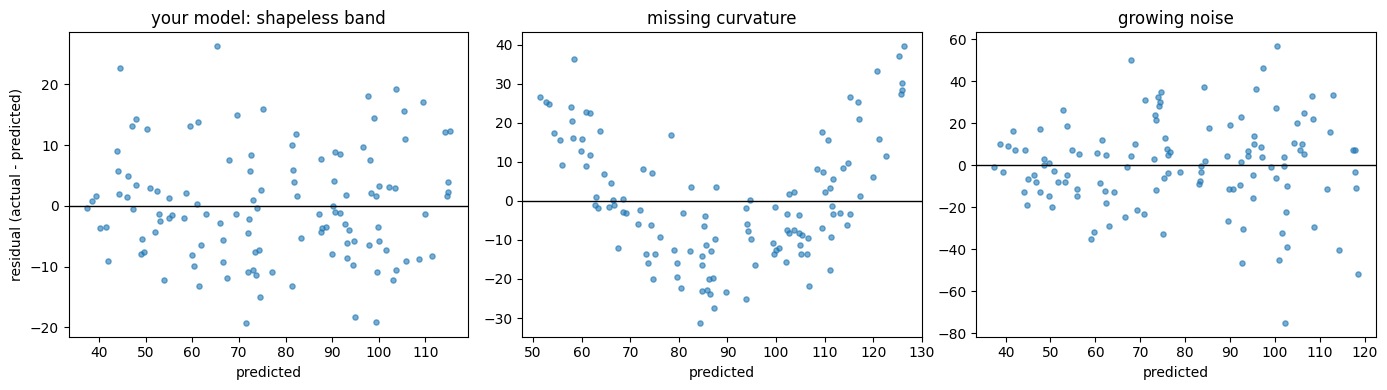

In [ ]:
curved = sales + 0.25 * (temperature - 21) ** 2        # a quadratic truth fitted with a line
funnel = 12 + 3.1 * temperature + rng.normal(0, 1, n) * temperature   # noise that grows with x

if not ready(theta_hat):
    print("Finish exercise 3, then run this cell.")
else:
    panels = [("your model: shapeless band", temperature, sales, theta_hat),
              ("missing curvature", temperature, curved, least_squares(temperature, curved)),
              ("growing noise", temperature, funnel, least_squares(temperature, funnel))]

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, (title, x, y, th) in zip(axes, panels):
        r = np.asarray(y) - predict(x, th)
        ax.scatter(predict(x, th), r, s=14, alpha=0.6)
        ax.axhline(0, color="k", lw=1)
        ax.set_title(title); ax.set_xlabel("predicted")
    axes[0].set_ylabel("residual (actual - predicted)")
    plt.tight_layout()

- **Left** — no structure. The line has extracted what there was to extract.
- **Middle** — a smile. The relationship bends and a straight line cannot follow it; add a squared
  term or use a non-linear model.
- **Right** — a funnel. The model is unbiased but its errors grow with the prediction, so a single
  RMSE flatters the small end and understates the big one.

**Rule of thumb:** the MSE tells you *how much* you are wrong; the residual plot tells you *why*.
Never report one without having looked at the other.

## What to take away

1. **A linear model is two numbers**, and both should mean something in the units of your problem.
2. **A cost function turns taste into arithmetic** — and squared error is the one with an exact
   solution.
3. **For least squares you do not search, you solve.** Closed form for one feature, the normal
   equation for many.
4. **The bias column** is how an intercept becomes an ordinary weight.
5. **`pinv` over `inv`**, so a degenerate matrix degrades instead of crashing.
6. **Residuals are the diagnosis.** A shapeless band is success; a curve or a funnel names the
   problem for you.

### Take it home
In your project, generalise `least_squares` into a class that takes a matrix `X` (with its bias
column) and returns a vector `theta`. Verify it twice: against the data-generating numbers, and
against the residual-mean-zero property above.